In [2]:
import os
import numpy as np
import cv2
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.decomposition import PCA
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import classification_report
from sklearn.metrics import accuracy_score
from sklearn.preprocessing import StandardScaler



In [3]:
def load_images_from_folder(dataset_path, image_size=(100, 100)):
    X = []
    y = []
    labels = os.listdir(dataset_path)
    
    for label in labels:
        person_folder = os.path.join(dataset_path, label)
        if not os.path.isdir(person_folder):
            continue
        for filename in os.listdir(person_folder):
            img_path = os.path.join(person_folder, filename)
            img = cv2.imread(img_path, cv2.IMREAD_GRAYSCALE)
            if img is not None:
                img = cv2.resize(img, image_size)
                X.append(img.flatten())
                y.append(label)
    
    return np.array(X), np.array(y)


In [4]:
dataset_path = "C:/Users/hp/Downloads/dataset/dataset/faces/"
y=[]  # Replace with your actual dataset path
X, y = load_images_from_folder(dataset_path)
print("Dataset loaded. Total samples:", len(X))


Dataset loaded. Total samples: 450


In [5]:

# Normalize the pixel values to be between 0 and 1
X = X / 255.0

In [6]:
# Encode labels to integers
label_encoder = LabelEncoder()
y_encoded = label_encoder.fit_transform(y)

# Split the dataset into training and testing sets (80-20 split)
X_train, X_test, y_train, y_test = train_test_split(X, y_encoded, test_size=0.2, random_state=42)




In [20]:
# Apply PCA for dimensionality reduction
pca = PCA(n_components=0.95)  # Retain 95% of variance
X_train_pca = pca.fit_transform(X_train)
X_test_pca = pca.transform(X_test)

# Scale the data
scaler = StandardScaler()
X_train_pca = scaler.fit_transform(X_train_pca)
X_test_pca = scaler.transform(X_test_pca)


In [104]:
# Initialize and train the MLP Classifier
mlp = MLPClassifier(hidden_layer_sizes=(256, 198), max_iter=1000, activation='relu', solver='adam', random_state=42)
mlp.fit(X_train_pca, y_train)




MLPClassifier(hidden_layer_sizes=(256, 198), max_iter=1000, random_state=42)

In [105]:
y_pred = mlp.predict(X_test_pca)
accuracy = accuracy_score(y_test, y_pred)
print(f"Accuracy: {accuracy * 100:.2f}%")
print("\nClassification Report:\n", classification_report(y_test, y_pred, target_names=label_encoder.classes_))


Accuracy: 81.11%

Classification Report:
               precision    recall  f1-score   support

       Aamir       0.83      0.83      0.83        12
        Ajay       0.87      0.93      0.90        14
      Akshay       0.80      0.89      0.84         9
        Alia       0.71      0.71      0.71         7
     Amitabh       1.00      1.00      1.00         8
     Deepika       0.67      0.75      0.71         8
       Disha       0.50      0.83      0.62         6
      Farhan       0.92      0.86      0.89        14
      Ileana       1.00      0.50      0.67        12

    accuracy                           0.81        90
   macro avg       0.81      0.81      0.80        90
weighted avg       0.84      0.81      0.81        90



In [106]:
# Evaluate the model on the test data
y_pred = mlp.predict(X_test_pca)

# Print accuracy and classification report
accuracy = accuracy_score(y_test, y_pred)
print(f"Accuracy: {accuracy * 100:.2f}%\n")

print("Classification Report:")
print(classification_report(y_test, y_pred, target_names=label_encoder.classes_))


Accuracy: 81.11%

Classification Report:
              precision    recall  f1-score   support

       Aamir       0.83      0.83      0.83        12
        Ajay       0.87      0.93      0.90        14
      Akshay       0.80      0.89      0.84         9
        Alia       0.71      0.71      0.71         7
     Amitabh       1.00      1.00      1.00         8
     Deepika       0.67      0.75      0.71         8
       Disha       0.50      0.83      0.62         6
      Farhan       0.92      0.86      0.89        14
      Ileana       1.00      0.50      0.67        12

    accuracy                           0.81        90
   macro avg       0.81      0.81      0.80        90
weighted avg       0.84      0.81      0.81        90



In [112]:
from sklearn.neighbors import KNeighborsClassifier
k_values = list(range(1, 21))
accuracies = []

for k in k_values:
    knn = KNeighborsClassifier(n_neighbors=k)
    knn.fit(X_train_pca, y_train)
    y_pred = knn.predict(X_test_pca)
    acc = accuracy_score(y_test, y_pred)
    accuracies.append(acc)
    print(f"K={k}: Accuracy = {acc * 100:.2f}%")


K=1: Accuracy = 50.00%
K=2: Accuracy = 50.00%
K=3: Accuracy = 41.11%
K=4: Accuracy = 38.89%
K=5: Accuracy = 36.67%
K=6: Accuracy = 35.56%
K=7: Accuracy = 34.44%
K=8: Accuracy = 31.11%
K=9: Accuracy = 27.78%
K=10: Accuracy = 26.67%
K=11: Accuracy = 25.56%
K=12: Accuracy = 20.00%
K=13: Accuracy = 21.11%
K=14: Accuracy = 24.44%
K=15: Accuracy = 21.11%
K=16: Accuracy = 21.11%
K=17: Accuracy = 22.22%
K=18: Accuracy = 22.22%
K=19: Accuracy = 18.89%
K=20: Accuracy = 15.56%


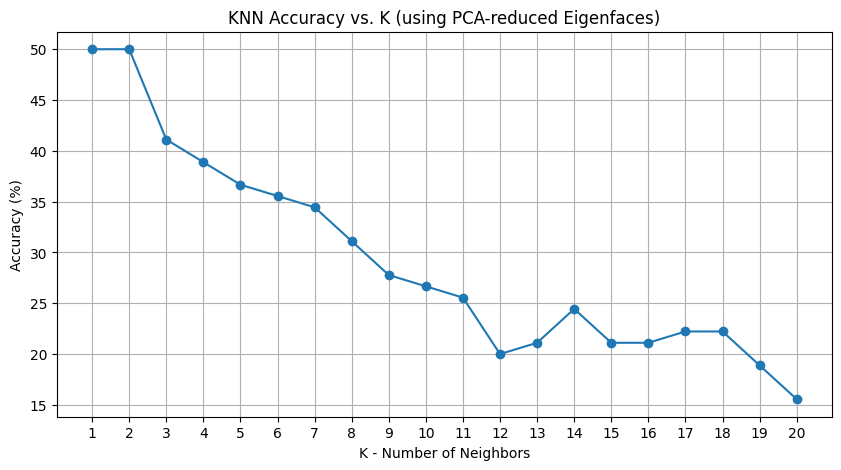

In [113]:
plt.figure(figsize=(10, 5))
plt.plot(k_values, [a * 100 for a in accuracies], marker='o')
plt.title('KNN Accuracy vs. K (using PCA-reduced Eigenfaces)')
plt.xlabel('K - Number of Neighbors')
plt.ylabel('Accuracy (%)')
plt.grid(True)
plt.xticks(k_values)
plt.show()


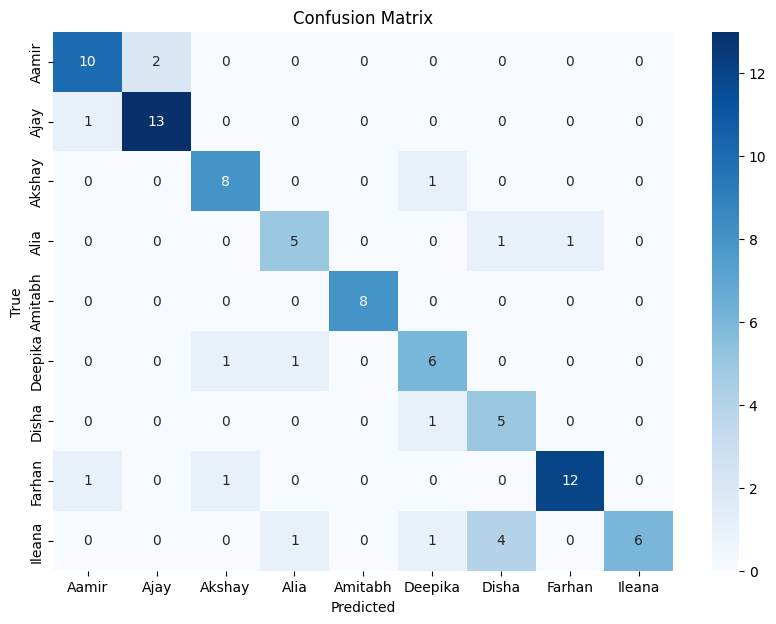

In [109]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import classification_report, accuracy_score, confusion_matrix
cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(10, 7))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=label_encoder.classes_,
            yticklabels=label_encoder.classes_)
plt.xlabel("Predicted")
plt.ylabel("True")
plt.title("Confusion Matrix")
plt.show()


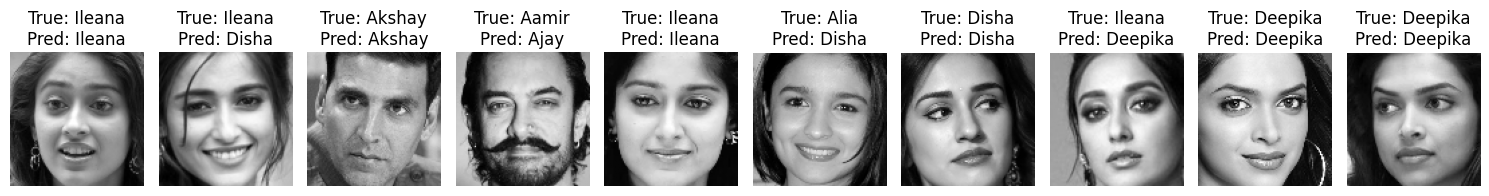

In [110]:
from sklearn.preprocessing import LabelEncoder
import matplotlib.pyplot as plt

# Function to plot predictions
def plot_predictions(X_test_raw, y_test, y_pred, label_encoder, count=10):
    plt.figure(figsize=(15, 4))
    for i in range(count):
        plt.subplot(1, count, i+1)
        plt.imshow(X_test_raw[i].reshape(100, 100), cmap='gray')
        plt.title(f"True: {label_encoder.inverse_transform([y_test[i]])[0]}\nPred: {label_encoder.inverse_transform([y_pred[i]])[0]}")
        plt.axis('off')
    plt.tight_layout()
    plt.show()

# Correct call
plot_predictions(X_test, y_test, y_pred, label_encoder)

